In [1]:
import torch
import pysiglib.torch_api as pysiglib
import pandas as pd
import numpy as np
import time
import gc

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
df = pd.read_csv('datasets/heston.csv')

In [4]:
paths = np.array(df['history_S'].str.split(',').tolist(), dtype=float)
paths = torch.from_numpy(paths).float().unsqueeze(2)

In [5]:
paths.shape

torch.Size([10000, 151, 1])

In [6]:
# Plot time taken and memory usage for different degrees of the signature computed on the GPU
times = []
mems = []

# Initialise pysiglib cache 
sig = pysiglib.sig(paths.to(device), 1, time_aug=True, lead_lag=True)

for degree in range(1, 11):
    start_time = time.time()
    sig = pysiglib.sig(paths.to(device), degree, time_aug=True, lead_lag=True)
    end_time = time.time()
    print(f"Degree: {degree}, Time taken: {end_time - start_time:.4f} seconds, Memory usage: {torch.cuda.memory_allocated(device) / (1024 ** 2):.2f} MB")
    times.append(end_time - start_time)
    mems.append(torch.cuda.memory_allocated(device) / (1024 ** 2))
    del sig  # Free up memory for the next iteration
    gc.collect()  # Run garbage collection to free up memory
    torch.cuda.empty_cache()  # Clear the GPU cache to free up memory

Degree: 1, Time taken: 0.0018 seconds, Memory usage: 0.11 MB
Degree: 2, Time taken: 0.0021 seconds, Memory usage: 0.46 MB
Degree: 3, Time taken: 0.0033 seconds, Memory usage: 1.49 MB
Degree: 4, Time taken: 0.0051 seconds, Memory usage: 4.58 MB
Degree: 5, Time taken: 0.0105 seconds, Memory usage: 14.24 MB
Degree: 6, Time taken: 0.0337 seconds, Memory usage: 42.00 MB
Degree: 7, Time taken: 0.1203 seconds, Memory usage: 126.00 MB
Degree: 8, Time taken: 0.4009 seconds, Memory usage: 376.00 MB
Degree: 9, Time taken: 1.4344 seconds, Memory usage: 1126.21 MB
Degree: 10, Time taken: 5.1235 seconds, Memory usage: 3378.75 MB


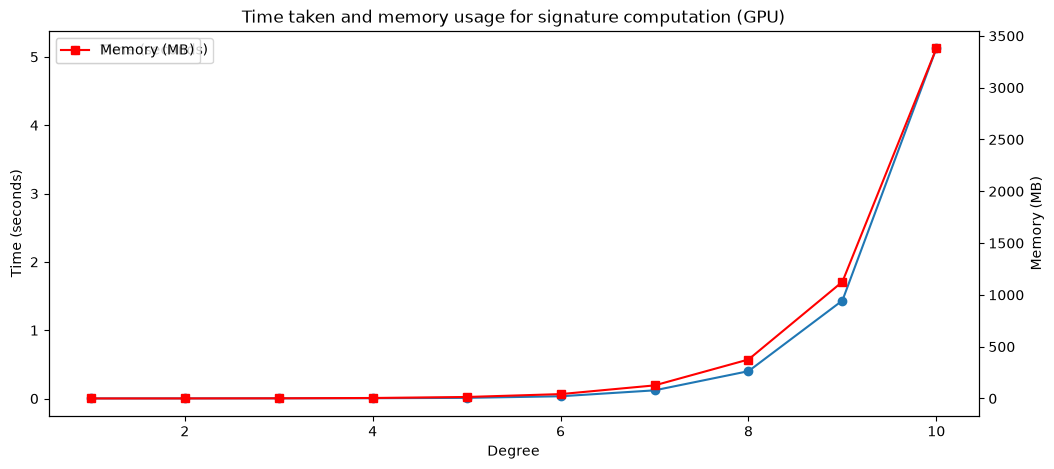

In [7]:
import matplotlib.pyplot as plt
%matplotlib inline

# Plot times and memory usage as a function of degree on the same plot with two y-axes
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(range(1, 11), times, marker='o', label='Time (seconds)')
ax1.set_xlabel('Degree')
ax1.set_ylabel('Time (seconds)')
ax1.tick_params(axis='y')

ax2 = ax1.twinx()
ax2.plot(range(1, 11), mems, marker='s', label='Memory (MB)', color='red')
ax2.set_ylabel('Memory (MB)')
ax2.tick_params(axis='y')

ax1.legend(loc='upper left')
ax2.legend(loc='upper left')
plt.title('Time taken and memory usage for signature computation (GPU)')
plt.show()

In [8]:
# Time taken on CPU
times_cpu = []
device = 'cpu'
for degree in range(1, 10):
    start_time = time.time()
    sig_cpu = pysiglib.sig(paths, degree, time_aug=True, lead_lag=True)
    end_time = time.time()
    print(f"Degree: {degree}, Time taken: {end_time - start_time:.4f} seconds")
    times_cpu.append(end_time - start_time)
    del sig_cpu  # Free up memory for the next iteration
    gc.collect()  # Run garbage collection to free up memory

/home/gaurav/.venvs/sig_nsde/lib/python3.12/site-packages/torch/autograd/function.py:625: UserWarning: Detected a non-contiguous or view-based array. Such arrays will be cloned to ensure safe access. To avoid this overhead, pass arrays that are both contiguous and own their data. This warning will only appear once per session.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Degree: 1, Time taken: 0.0073 seconds
Degree: 2, Time taken: 0.0467 seconds
Degree: 3, Time taken: 0.0732 seconds
Degree: 4, Time taken: 0.1475 seconds
Degree: 5, Time taken: 0.3463 seconds
Degree: 6, Time taken: 0.9487 seconds
Degree: 7, Time taken: 2.6642 seconds
Degree: 8, Time taken: 7.6731 seconds
Degree: 9, Time taken: 25.2471 seconds


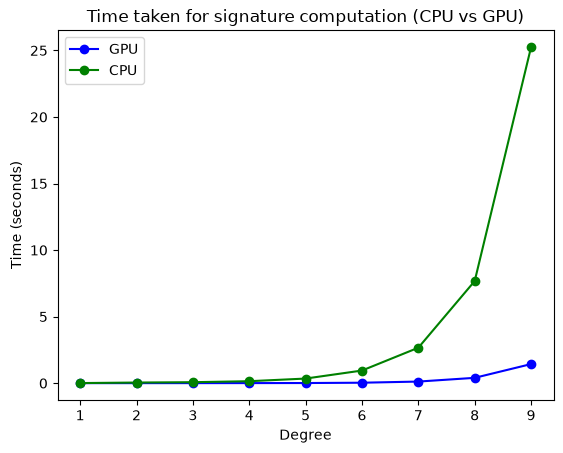

In [9]:
# Time taken on CPU against GPU
times_gpu = times[:9]
plt.plot(range(1, 10), times_gpu, marker='o', label='GPU', color='blue')
plt.plot(range(1, 10), times_cpu, marker='o', label='CPU', color='green')
plt.xlabel('Degree')
plt.ylabel('Time (seconds)')
plt.title('Time taken for signature computation (CPU vs GPU)')
plt.legend()
plt.show()

In [10]:
import torchsde

# GPU computation with gradients

from create_heston_data import HestonSDE, simulate_heston_paths

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # reset (was 'cpu')
dtype = torch.float64
use_cuda = device.type == "cuda"

def sync():
    if use_cuda:
        torch.cuda.synchronize()

def param(v):
    return torch.tensor(v, dtype=dtype, device=device, requires_grad=True)

mu, kappa, theta, sigma, rho = map(param, [0.06, 2.0, 0.01, 0.1, -0.7])

sde = HestonSDE(mu=mu, kappa=kappa, theta=theta, sigma=sigma, rho=rho).to(device)

batch_size, n_steps = 10000, 150
S0, V0, DT = 1.0, 0.1, 1.0 / 252.0

ts = torch.linspace(0.0, DT * n_steps, n_steps + 1, dtype=dtype, device=device)
y0 = torch.tensor([S0, V0], dtype=dtype, device=device).repeat(batch_size, 1)

# --- Simulate once (graph back to the Heston params is kept) ---
sim = torchsde.sdeint(sde, y0, ts=ts, method='euler', dt=DT)    # (T, B, 2)
paths_sim = sim.permute(1, 0, 2)[:, :, 0].unsqueeze(2)

In [11]:
sig = pysiglib.sig(paths_sim, 3, time_aug=True, lead_lag=True)
sig.sum().backward()
for name, p in zip(["mu", "kappa", "theta", "sigma", "rho"], [mu, kappa, theta, sigma, rho]):
    print(name, p.grad)
for p in [mu, kappa, theta, sigma, rho]:
    p.grad = None

mu tensor(31495.5870, device='cuda:0', dtype=torch.float64)
kappa tensor(-117.3356, device='cuda:0', dtype=torch.float64)
theta tensor(4103.5131, device='cuda:0', dtype=torch.float64)
sigma tensor(-151.8893, device='cuda:0', dtype=torch.float64)
rho tensor(-4.3628, device='cuda:0', dtype=torch.float64)


In [12]:
# Benchmark the signature forward + backward only.
# Detach to a fresh leaf so the SDE solver's backward pass isn't included in the timings.
paths_leaf = paths_sim.detach().clone().requires_grad_(True)

# Warm-up (initialises pysiglib cache / CUDA kernels)
s = pysiglib.sig(paths_leaf, 1, time_aug=True, lead_lag=True)
s.sum().backward()
paths_leaf.grad = None
del s; gc.collect()
if use_cuda: torch.cuda.empty_cache()

degrees = range(1, 10)   # adjust upper bound to what fits in memory
fwd_times, bwd_times, peak_mems = [], [], []

for degree in degrees:
    if use_cuda:
        torch.cuda.reset_peak_memory_stats(device)

    sync(); t0 = time.perf_counter()
    sig = pysiglib.sig(paths_leaf, degree, time_aug=True, lead_lag=True)
    loss = sig.sum()
    sync(); t1 = time.perf_counter()

    loss.backward()
    sync(); t2 = time.perf_counter()

    fwd_times.append(t1 - t0)
    bwd_times.append(t2 - t1)
    peak_mems.append(torch.cuda.max_memory_allocated(device) / 1024**2 if use_cuda else float('nan'))

    print(f"Degree {degree}: fwd {fwd_times[-1]:.4f}s, bwd {bwd_times[-1]:.4f}s, "
          f"peak mem {peak_mems[-1]:.1f} MB")

    paths_leaf.grad = None
    del sig, loss
    gc.collect()
    if use_cuda: torch.cuda.empty_cache()

Degree 1: fwd 0.0021s, bwd 0.0783s, peak mem 71.3 MB
Degree 2: fwd 0.0068s, bwd 0.1796s, peak mem 70.0 MB
Degree 3: fwd 0.0145s, bwd 0.3057s, peak mem 74.2 MB
Degree 4: fwd 0.0604s, bwd 0.5652s, peak mem 86.1 MB
Degree 5: fwd 0.2468s, bwd 1.5480s, peak mem 124.2 MB
Degree 6: fwd 1.0247s, bwd 5.7695s, peak mem 236.2 MB
Degree 7: fwd 4.1983s, bwd 32.0794s, peak mem 588.6 MB
Degree 8: fwd 16.5730s, bwd 139.2542s, peak mem 1651.7 MB
Degree 9: fwd 63.2684s, bwd 564.5483s, peak mem 4843.1 MB


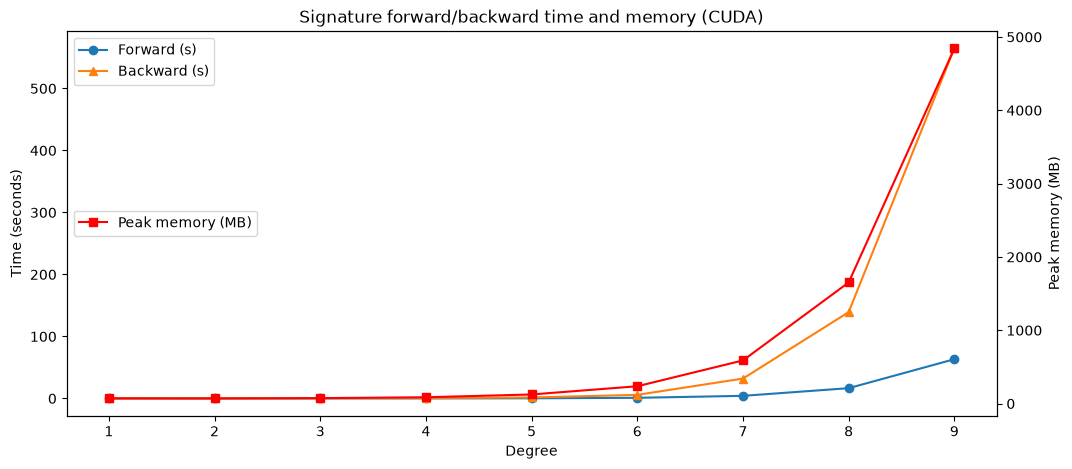

In [15]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(degrees, fwd_times, marker='o', label='Forward (s)')
ax1.plot(degrees, bwd_times, marker='^', label='Backward (s)')
ax1.set_xlabel('Degree'); ax1.set_ylabel('Time (seconds)')
ax1.legend(loc='upper left')

if use_cuda:
    ax2 = ax1.twinx()
    ax2.plot(degrees, peak_mems, marker='s', color='red', label='Peak memory (MB)')
    ax2.set_ylabel('Peak memory (MB)')
    ax2.legend(loc='center left')

plt.title(f'Signature forward/backward time and memory ({device.type.upper()})')
plt.show()